# Part 3: Macro-Factor Tactical Asset Allocation

## 1. Research Objective

Part 1 constructed two risk-based portfolios:

1. Fixed ERC portfolio;
2. Rolling ERC portfolio.

The empirical results showed that the Rolling ERC portfolio produced a higher total return and CAGR than the Fixed ERC portfolio over the 2013–2025 out-of-sample period. Therefore, the Rolling ERC portfolio is selected as the strategic benchmark.

Part 2 introduced five macroeconomic factors:

1. Growth;
2. Inflation;
3. Interest Rates;
4. Credit Conditions;
5. Risk Sentiment.

For each asset, a 60-month rolling predictive regression was estimated:

$$
R_{i,t+1}^{e}
=
\alpha_{i,t}
+
\boldsymbol{\beta}_{i,t}^{\top}
\mathbf F_t
+
\varepsilon_{i,t+1}.
$$

The model generated out-of-sample expected excess returns for seven asset classes from January 2013 through December 2025.

Although individual monthly point forecasts were noisy, the model produced:

$$
\text{Mean Monthly Rank IC}=0.1053,
$$

$$
\text{Positive Rank IC Ratio}=55.13\%,
$$

and:

$$
\text{Newey-West }t\text{-statistic}=3.1914.
$$

The corresponding Newey-West p-value was:

$$
p=0.001416.
$$

These results suggest that the macro-factor model contains statistically significant information about the subsequent relative performance of the seven asset classes.

The objective of Part 3 is to convert this predictive information into controlled tactical portfolio tilts and determine whether the macro overlay improves the performance of the Rolling ERC strategic benchmark.

The final tactical portfolio is defined as:

$$
\mathbf w_t^{Tactical}
=
\mathbf w_t^{Strategic}
+
\Delta\mathbf w_t^{Macro},
$$

where:

- $\mathbf w_t^{Strategic}$ represents the Rolling ERC benchmark weights;
- $\Delta\mathbf w_t^{Macro}$ represents the macro-driven tactical tilts;
- $\mathbf w_t^{Tactical}$ represents the final portfolio weights.

To preserve the portfolio's full-investment condition, the tactical tilts will satisfy:

$$
\sum_{i=1}^{7}
\Delta w_{i,t}^{Macro}
=
0.
$$

Therefore, the macro overlay reallocates capital among the seven risky assets rather than creating additional leverage.

The final empirical comparison will include:

1. Fixed ERC;
2. Rolling ERC;
3. Macro Tactical ERC.

This comparison separates the value added by dynamic risk allocation from the additional value provided by macroeconomic information.

In [1]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from pandas_datareader import data as pdr

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
pd.options.display.float_format = "{:,.6f}".format

In [2]:
# ---------------------------------------------------------
# Part 3: Macro Tactical Asset Allocation
# Load Part 1 and Part 2 results
# ---------------------------------------------------------

strategic_weights = pd.read_csv(
    "monthly_rolling_erc_weights_2013_2025.csv",
    index_col=0,
    parse_dates=True
)

rolling_erc_returns = pd.read_csv(
    "rolling_erc_returns_2013_2025.csv",
    index_col=0,
    parse_dates=True
).squeeze("columns")

fixed_erc_returns = pd.read_csv(
    "fixed_erc_returns_2013_2025.csv",
    index_col=0,
    parse_dates=True
).squeeze("columns")

all_asset_returns = pd.read_csv(
    "monthly_all_asset_returns_2013_2025.csv",
    index_col=0,
    parse_dates=True
)

In [3]:
# ---------------------------------------------------------
# Load Part 2 rolling macro predictions
# ---------------------------------------------------------

rolling_predictions = pd.read_csv(
    "rolling_predicted_excess_returns_2013_2025.csv",
    index_col=0,
    parse_dates=True
)

rolling_realized_returns = pd.read_csv(
    "rolling_realized_excess_returns_2013_2025.csv",
    index_col=0,
    parse_dates=True
)

rolling_predictions.index.name = "Return_Date"
rolling_realized_returns.index.name = "Return_Date"

print(
    "Rolling predictions:",
    rolling_predictions.shape
)

print(
    "Rolling realized excess returns:",
    rolling_realized_returns.shape
)

Rolling predictions: (156, 7)
Rolling realized excess returns: (156, 7)


In [4]:
# ---------------------------------------------------------
# Check alignment across Part 1 and Part 2
# ---------------------------------------------------------

print("Strategic weights:", strategic_weights.shape)
print("All asset returns:", all_asset_returns.shape)
print("Rolling ERC returns:", rolling_erc_returns.shape)
print("Fixed ERC returns:", fixed_erc_returns.shape)
print("Rolling predictions:", rolling_predictions.shape)

print(
    "\nPrediction dates match strategic-weight dates:",
    rolling_predictions.index.equals(
        strategic_weights.index
    )
)

print(
    "Strategic-weight dates match return dates:",
    strategic_weights.index.equals(
        all_asset_returns.index
    )
)

print(
    "All monthly weights sum to one:",
    np.allclose(
        strategic_weights.sum(axis=1),
        1.0
    )
)

Strategic weights: (156, 8)
All asset returns: (156, 8)
Rolling ERC returns: (156,)
Fixed ERC returns: (156,)
Rolling predictions: (156, 7)

Prediction dates match strategic-weight dates: True
Strategic-weight dates match return dates: True
All monthly weights sum to one: True


## 2. From Expected Returns to Cross-Sectional Signals

The macro-factor model generates predicted excess returns for the seven risky assets. However, the predicted return values should not be used directly as portfolio weights.

The out-of-sample evidence from Part 2 primarily supports the model's cross-sectional ranking ability:

$$
\text{Mean Monthly Rank IC}=0.1053.
$$

Therefore, the tactical allocation process uses the relative ranking of predicted returns rather than relying on the exact magnitude of each return forecast.

For each month, the seven assets are ranked from the lowest predicted excess return to the highest predicted excess return.

The ranks are transformed into centered scores:

$$
s_{i,t}
=
\frac{
Rank_{i,t}-\frac{N+1}{2}
}{
\frac{N-1}{2}
},
$$

where:

$$
N=7.
$$

The resulting scores are:

$$
-1,\;
-\frac{2}{3},\;
-\frac{1}{3},\;
0,\;
\frac{1}{3},\;
\frac{2}{3},\;
1.
$$

The asset with the highest predicted excess return receives a score of $+1$, while the asset with the lowest predicted excess return receives a score of $-1$.

Because the scores are centered:

$$
\sum_{i=1}^{7}s_{i,t}=0.
$$

This makes it possible to construct a zero-sum tactical overlay that overweights assets with stronger macro signals and underweights assets with weaker macro signals.

In [5]:
# ---------------------------------------------------------
# Align prediction column names with strategic-weight names
# ---------------------------------------------------------

prediction_column_mapping = {
    "US_Equity_Excess":
        "US_Equity",

    "International_Equity_Excess":
        "International_Equity",

    "Treasury_Excess":
        "Treasury",

    "Investment_Grade_Credit_Excess":
        "Investment_Grade_Credit",

    "High_Yield_Credit_Excess":
        "High_Yield_Credit",

    "Commodities_Excess":
        "Commodities",

    "Gold_Excess":
        "Gold"
}

predicted_asset_returns = (
    rolling_predictions
    .rename(
        columns=prediction_column_mapping
    )
)

In [6]:
# ---------------------------------------------------------
# Define the seven risky assets
# ---------------------------------------------------------

risky_asset_names = [
    "US_Equity",
    "International_Equity",
    "Treasury",
    "Investment_Grade_Credit",
    "High_Yield_Credit",
    "Commodities",
    "Gold"
]

predicted_asset_returns = (
    predicted_asset_returns[
        risky_asset_names
    ]
)

predicted_asset_returns.head()

,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold
Return_Date,,,,,,,
2013-01-31,0.005919,-0.000417,0.006991,0.000446,-0.007222,0.010423,0.013942
2013-02-28,0.013493,0.009417,0.003014,0.000775,0.000281,0.023965,0.006574
2013-03-31,0.012435,0.009737,0.007172,0.010641,0.014325,0.000118,0.011046
2013-04-30,0.012739,0.007807,0.005226,0.008491,0.012440,0.006491,0.007056
2013-05-31,0.014769,0.011094,0.005107,0.007870,0.014212,0.006764,0.014641


In [7]:
# ---------------------------------------------------------
# Rank assets by predicted excess return each month
# ---------------------------------------------------------

predicted_return_ranks = (
    predicted_asset_returns
    .rank(
        axis=1,
        method="average",
        ascending=True
    )
)

predicted_return_ranks.head()

,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold
Return_Date,,,,,,,
2013-01-31,4.000000,2.000000,5.000000,3.000000,1.000000,6.000000,7.000000
2013-02-28,6.000000,5.000000,3.000000,2.000000,1.000000,7.000000,4.000000
2013-03-31,6.000000,3.000000,2.000000,4.000000,7.000000,1.000000,5.000000
2013-04-30,7.000000,4.000000,1.000000,5.000000,6.000000,2.000000,3.000000
2013-05-31,7.000000,4.000000,1.000000,3.000000,5.000000,2.000000,6.000000


In [8]:
# ---------------------------------------------------------
# Convert ranks into centered signals between -1 and +1
# ---------------------------------------------------------

NUMBER_OF_RISKY_ASSETS = len(
    risky_asset_names
)

rank_center = (
    NUMBER_OF_RISKY_ASSETS + 1
) / 2

rank_scale = (
    NUMBER_OF_RISKY_ASSETS - 1
) / 2

macro_rank_signals = (
    predicted_return_ranks
    -
    rank_center
) / rank_scale

macro_rank_signals.head()

,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold
Return_Date,,,,,,,
2013-01-31,0.000000,-0.666667,0.333333,-0.333333,-1.000000,0.666667,1.000000
2013-02-28,0.666667,0.333333,-0.333333,-0.666667,-1.000000,1.000000,0.000000
2013-03-31,0.666667,-0.333333,-0.666667,0.000000,1.000000,-1.000000,0.333333
2013-04-30,1.000000,0.000000,-1.000000,0.333333,0.666667,-0.666667,-0.333333
2013-05-31,1.000000,0.000000,-1.000000,-0.333333,0.333333,-0.666667,0.666667


In [9]:
# ---------------------------------------------------------
# Validate macro rank signals
# ---------------------------------------------------------

print(
    "Minimum signal:",
    macro_rank_signals.min().min()
)

print(
    "Maximum signal:",
    macro_rank_signals.max().max()
)

print(
    "All monthly signals sum to zero:",
    np.allclose(
        macro_rank_signals.sum(axis=1),
        0.0
    )
)

Minimum signal: -1.0
Maximum signal: 1.0
All monthly signals sum to zero: True


In [10]:
# ---------------------------------------------------------
# Inspect the first tactical signal month
# ---------------------------------------------------------

first_month_signal_check = pd.DataFrame({
    "Predicted Excess Return":
        predicted_asset_returns.iloc[0],

    "Predicted Rank":
        predicted_return_ranks.iloc[0],

    "Macro Rank Signal":
        macro_rank_signals.iloc[0]
})

first_month_signal_check = (
    first_month_signal_check
    .sort_values(
        "Predicted Rank",
        ascending=False
    )
)

first_month_signal_check.style.format({
    "Predicted Excess Return": "{:.2%}",
    "Predicted Rank": "{:.0f}",
    "Macro Rank Signal": "{:.3f}"
})

,Predicted Excess Return,Predicted Rank,Macro Rank Signal
Gold,1.39%,7,1.000
Commodities,1.04%,6,0.667
Treasury,0.70%,5,0.333
US_Equity,0.59%,4,0.000
Investment_Grade_Credit,0.04%,3,-0.333
International_Equity,-0.04%,2,-0.667
High_Yield_Credit,-0.72%,1,-1.000


## 3. Construction of Tactical Weight Tilts

The centered macro rank signals are converted into tactical weight adjustments using a predetermined tilt parameter:

$$
\Delta w_{i,t}^{Macro}
=
\lambda s_{i,t},
$$

where:

- $s_{i,t}$ is the centered macro rank signal;
- $\lambda$ controls the maximum tactical adjustment;
- $\Delta w_{i,t}^{Macro}$ is the tactical change in the asset's portfolio weight.

The baseline specification uses:

$$
\lambda=2\%.
$$

Therefore, the highest-ranked asset receives a maximum overweight of two percentage points, while the lowest-ranked asset receives a maximum underweight of two percentage points.

For seven assets, the possible tactical adjustments are:

$$
-2.00\%,
-1.33\%,
-0.67\%,
0.00\%,
0.67\%,
1.33\%,
2.00\%.
$$

Because the centered signals sum to zero:

$$
\sum_{i=1}^{7}s_{i,t}=0,
$$

the tactical adjustments also sum to zero:

$$
\sum_{i=1}^{7}\Delta w_{i,t}^{Macro}=0.
$$

The final tactical weights are:

$$
w_{i,t}^{Tactical}
=
w_{i,t}^{Strategic}
+
\Delta w_{i,t}^{Macro}.
$$

The 5% cash allocation remains unchanged in the baseline tactical strategy. Therefore, the macro overlay reallocates capital only among the seven risky assets.

The final portfolio continues to satisfy:

$$
\sum_{i=1}^{7}w_{i,t}^{Tactical}
+
w_{Cash,t}
=
1.
$$

In [11]:
# ---------------------------------------------------------
# Convert macro rank signals into tactical tilts
# ---------------------------------------------------------

MAXIMUM_TACTICAL_TILT = 0.02

macro_tactical_tilts = (
    macro_rank_signals
    *
    MAXIMUM_TACTICAL_TILT
)

macro_tactical_tilts.head()

,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold
Return_Date,,,,,,,
2013-01-31,0.000000,-0.013333,0.006667,-0.006667,-0.020000,0.013333,0.020000
2013-02-28,0.013333,0.006667,-0.006667,-0.013333,-0.020000,0.020000,0.000000
2013-03-31,0.013333,-0.006667,-0.013333,0.000000,0.020000,-0.020000,0.006667
2013-04-30,0.020000,0.000000,-0.020000,0.006667,0.013333,-0.013333,-0.006667
2013-05-31,0.020000,0.000000,-0.020000,-0.006667,0.006667,-0.013333,0.013333


In [12]:
# ---------------------------------------------------------
# Add a zero tactical tilt for cash
# ---------------------------------------------------------

complete_tactical_tilts = pd.DataFrame(
    0.0,
    index=strategic_weights.index,
    columns=strategic_weights.columns
)

complete_tactical_tilts[
    risky_asset_names
] = macro_tactical_tilts[
    risky_asset_names
]

complete_tactical_tilts["Cash"] = 0.0

complete_tactical_tilts.head()

,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold,Cash
Date,,,,,,,,
2013-01-31,0.000000,-0.013333,0.006667,-0.006667,-0.020000,0.013333,0.020000,0.000000
2013-02-28,0.013333,0.006667,-0.006667,-0.013333,-0.020000,0.020000,0.000000,0.000000
2013-03-31,0.013333,-0.006667,-0.013333,0.000000,0.020000,-0.020000,0.006667,0.000000
2013-04-30,0.020000,0.000000,-0.020000,0.006667,0.013333,-0.013333,-0.006667,0.000000
2013-05-31,0.020000,0.000000,-0.020000,-0.006667,0.006667,-0.013333,0.013333,0.000000


In [13]:
# ---------------------------------------------------------
# Add tactical tilts to Rolling ERC strategic weights
# ---------------------------------------------------------

tactical_weights = (
    strategic_weights
    +
    complete_tactical_tilts
)

tactical_weights.index.name = "Return_Date"

tactical_weights.head()

,US_Equity,International_Equity,Treasury,Investment_Grade_Credit,High_Yield_Credit,Commodities,Gold,Cash
Return_Date,,,,,,,,
2013-01-31,0.085983,0.047253,0.409066,0.139648,0.073846,0.085294,0.108911,0.050000
2013-02-28,0.099316,0.067253,0.395732,0.132981,0.073846,0.091960,0.088911,0.050000
2013-03-31,0.099316,0.053920,0.389066,0.146315,0.113846,0.051960,0.095578,0.050000
2013-04-30,0.105983,0.060586,0.382399,0.152981,0.107179,0.058627,0.082245,0.050000
2013-05-31,0.105983,0.060586,0.382399,0.139648,0.100513,0.058627,0.102245,0.050000


In [14]:
# ---------------------------------------------------------
# Validate tactical portfolio constraints
# ---------------------------------------------------------

print(
    "All tactical tilts sum to zero:",
    np.allclose(
        complete_tactical_tilts.sum(axis=1),
        0.0
    )
)

print(
    "All tactical weights sum to one:",
    np.allclose(
        tactical_weights.sum(axis=1),
        1.0
    )
)

print(
    "Cash remains at 5%:",
    np.allclose(
        tactical_weights["Cash"],
        0.05
    )
)

print(
    "Minimum tactical portfolio weight:",
    tactical_weights.min().min()
)

print(
    "Portfolio remains long-only:",
    (
        tactical_weights >= 0
    ).all().all()
)

All tactical tilts sum to zero: True
All tactical weights sum to one: True
Cash remains at 5%: True
Minimum tactical portfolio weight: 0.0390737654003136
Portfolio remains long-only: True


In [15]:
# ---------------------------------------------------------
# Inspect the first tactical allocation
# ---------------------------------------------------------

first_month_weight_comparison = pd.DataFrame({
    "Strategic Weight":
        strategic_weights.iloc[0],

    "Macro Tactical Tilt":
        complete_tactical_tilts.iloc[0],

    "Final Tactical Weight":
        tactical_weights.iloc[0]
})

first_month_weight_comparison.style.format(
    "{:.2%}"
)

,Strategic Weight,Macro Tactical Tilt,Final Tactical Weight
US_Equity,8.60%,0.00%,8.60%
International_Equity,6.06%,-1.33%,4.73%
Treasury,40.24%,0.67%,40.91%
Investment_Grade_Credit,14.63%,-0.67%,13.96%
High_Yield_Credit,9.38%,-2.00%,7.38%
Commodities,7.20%,1.33%,8.53%
Gold,8.89%,2.00%,10.89%
Cash,5.00%,0.00%,5.00%


In [16]:
# ---------------------------------------------------------
# Reconstruct Rolling ERC returns from imported data
# ---------------------------------------------------------

reconstructed_rolling_erc_returns = (
    all_asset_returns
    *
    strategic_weights
).sum(axis=1)

maximum_reconstruction_difference = (
    reconstructed_rolling_erc_returns
    -
    rolling_erc_returns
).abs().max()

print(
    "Maximum Rolling ERC reconstruction difference:",
    maximum_reconstruction_difference
)

print(
    "Rolling ERC reconstruction is correct:",
    np.allclose(
        reconstructed_rolling_erc_returns,
        rolling_erc_returns
    )
)

Maximum Rolling ERC reconstruction difference: 1.0950441942103595e-16
Rolling ERC reconstruction is correct: True


In [17]:
# ---------------------------------------------------------
# Calculate monthly Macro Tactical ERC returns
# ---------------------------------------------------------

macro_tactical_returns_gross = (
    all_asset_returns
    *
    tactical_weights
).sum(axis=1)

macro_tactical_returns_gross.name = (
    "Macro_Tactical_ERC_Gross"
)

macro_tactical_returns_gross.head()

Date
2013-01-31    0.000884
2013-02-28   -0.001846
2013-03-31    0.007770
2013-04-30    0.008056
2013-05-31   -0.025538
Name: Macro_Tactical_ERC_Gross, dtype: float64

In [18]:
# ---------------------------------------------------------
# Calculate monthly macro-overlay active returns
# ---------------------------------------------------------

macro_overlay_active_returns = (
    macro_tactical_returns_gross
    -
    rolling_erc_returns
)

macro_overlay_active_returns.name = (
    "Macro_Overlay_Active_Return"
)

macro_overlay_active_returns.head()

Date
2013-01-31   -0.000335
2013-02-28   -0.001263
2013-03-31    0.000486
2013-04-30    0.001518
2013-05-31    0.000517
Name: Macro_Overlay_Active_Return, dtype: float64

In [19]:
# ---------------------------------------------------------
# Calculate cumulative portfolio values
# ---------------------------------------------------------

fixed_erc_cumulative = (
    1 + fixed_erc_returns
).cumprod()

rolling_erc_cumulative = (
    1 + rolling_erc_returns
).cumprod()

macro_tactical_cumulative_gross = (
    1 + macro_tactical_returns_gross
).cumprod()

portfolio_cumulative_comparison = pd.concat(
    [
        fixed_erc_cumulative.rename(
            "Fixed ERC"
        ),

        rolling_erc_cumulative.rename(
            "Rolling ERC"
        ),

        macro_tactical_cumulative_gross.rename(
            "Macro Tactical ERC"
        )
    ],
    axis=1
)

portfolio_cumulative_comparison.tail()

,Fixed ERC,Rolling ERC,Macro Tactical ERC
Date,,,
2025-08-31,1.577263,1.639844,1.694800
2025-09-30,1.612234,1.686575,1.747274
2025-10-31,1.628823,1.706904,1.768930
2025-11-30,1.648614,1.731431,1.795149
2025-12-31,1.649080,1.737355,1.802457


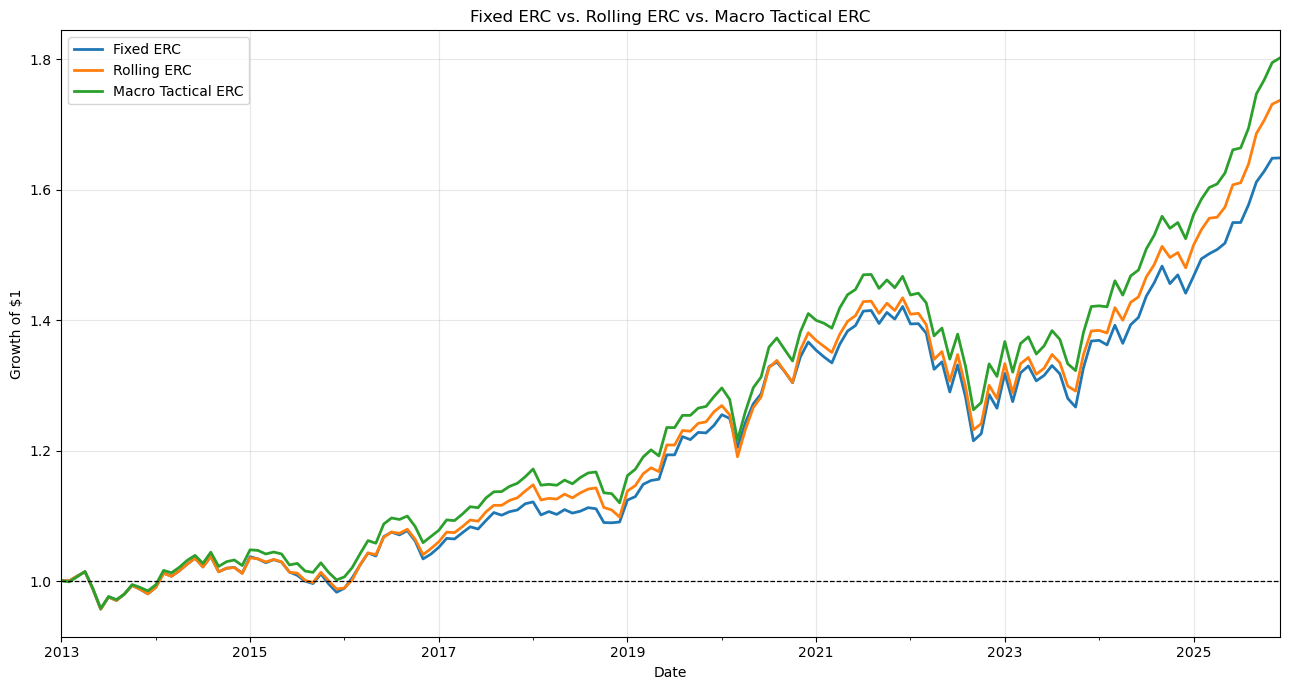

In [20]:
# ---------------------------------------------------------
# Plot cumulative portfolio performance
# ---------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(13, 7)
)

portfolio_cumulative_comparison.plot(
    ax=ax,
    linewidth=2
)

ax.axhline(
    y=1,
    color="black",
    linestyle="--",
    linewidth=0.9
)

ax.set_title(
    "Fixed ERC vs. Rolling ERC vs. Macro Tactical ERC"
)
ax.set_xlabel("Date")
ax.set_ylabel("Growth of $1")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [21]:
# ---------------------------------------------------------
# Define portfolio performance function
# ---------------------------------------------------------

def calculate_portfolio_performance(
    portfolio_returns,
    cash_returns
):

    number_of_months = len(
        portfolio_returns
    )

    number_of_years = (
        number_of_months / 12
    )

    cumulative_value = (
        1 + portfolio_returns
    ).cumprod()

    final_value = (
        cumulative_value.iloc[-1]
    )

    total_return = (
        final_value - 1
    )

    cagr = (
        final_value
        ** (1 / number_of_years)
        - 1
    )

    annualized_volatility = (
        portfolio_returns.std()
        *
        np.sqrt(12)
    )

    excess_returns = (
        portfolio_returns
        -
        cash_returns
    )

    sharpe_ratio = (
        excess_returns.mean() * 12
    ) / (
        excess_returns.std()
        *
        np.sqrt(12)
    )

    running_peak = (
        cumulative_value.cummax()
    )

    drawdown = (
        cumulative_value
        /
        running_peak
        -
        1
    )

    maximum_drawdown = (
        drawdown.min()
    )

    return pd.Series({
        "Final Value": final_value,
        "Total Return": total_return,
        "CAGR": cagr,
        "Annualized Volatility":
            annualized_volatility,
        "Sharpe Ratio": sharpe_ratio,
        "Maximum Drawdown":
            maximum_drawdown
    })

In [22]:
# ---------------------------------------------------------
# Compare gross portfolio performance
# ---------------------------------------------------------

cash_returns = all_asset_returns[
    "Cash"
]

gross_performance_comparison = pd.DataFrame({
    "Fixed ERC":
        calculate_portfolio_performance(
            fixed_erc_returns,
            cash_returns
        ),

    "Rolling ERC":
        calculate_portfolio_performance(
            rolling_erc_returns,
            cash_returns
        ),

    "Macro Tactical ERC":
        calculate_portfolio_performance(
            macro_tactical_returns_gross,
            cash_returns
        )
}).T

gross_performance_comparison.style.format({
    "Final Value": "${:.4f}",
    "Total Return": "{:.2%}",
    "CAGR": "{:.2%}",
    "Annualized Volatility": "{:.2%}",
    "Sharpe Ratio": "{:.3f}",
    "Maximum Drawdown": "{:.2%}"
})

,Final Value,Total Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
Fixed ERC,$1.6491,64.91%,3.92%,5.89%,0.408,-14.49%
Rolling ERC,$1.7374,73.74%,4.34%,6.02%,0.469,-14.12%
Macro Tactical ERC,$1.8025,80.25%,4.64%,6.01%,0.517,-14.11%


In [23]:
# ---------------------------------------------------------
# Calculate turnover only when target weights change
# ---------------------------------------------------------

def calculate_target_weight_turnover(
    target_weights
):

    turnover = (
        target_weights
        .diff()
        .abs()
        .sum(axis=1)
        *
        0.5
    )

    # Initial portfolio formation is excluded.
    turnover.iloc[0] = 0.0

    turnover.name = "Turnover"

    return turnover

In [24]:
# ---------------------------------------------------------
# Calculate strategy turnover
# ---------------------------------------------------------

# Fixed ERC keeps constant target weights.
# Initial portfolio formation is excluded.
fixed_erc_turnover = pd.Series(
    0.0,
    index=strategic_weights.index,
    name="Fixed ERC Turnover"
)

# Rolling ERC changes its strategic target weights annually.
rolling_erc_turnover = (
    calculate_target_weight_turnover(
        strategic_weights
    )
)

# Macro Tactical ERC may change its target weights monthly.
macro_tactical_turnover = (
    calculate_target_weight_turnover(
        tactical_weights
    )
)

In [25]:
# ---------------------------------------------------------
# Summarize strategy turnover
# ---------------------------------------------------------

turnover_summary = pd.DataFrame({
    "Average Monthly Turnover": [
        fixed_erc_turnover.mean(),
        rolling_erc_turnover.mean(),
        macro_tactical_turnover.mean()
    ],

    "Annualized Turnover": [
        fixed_erc_turnover.sum()
        / 13,

        rolling_erc_turnover.sum()
        / 13,

        macro_tactical_turnover.sum()
        / 13
    ],

    "Maximum Monthly Turnover": [
        fixed_erc_turnover.max(),
        rolling_erc_turnover.max(),
        macro_tactical_turnover.max()
    ],

    "Number of Rebalancing Months": [
        (fixed_erc_turnover > 1e-10).sum(),
        (rolling_erc_turnover > 1e-10).sum(),
        (macro_tactical_turnover > 1e-10).sum()
    ]
}, index=[
    "Fixed ERC",
    "Rolling ERC",
    "Macro Tactical ERC"
])

turnover_summary.style.format({
    "Average Monthly Turnover": "{:.2%}",
    "Annualized Turnover": "{:.2%}",
    "Maximum Monthly Turnover": "{:.2%}",
    "Number of Rebalancing Months": "{:.0f}"
})

,Average Monthly Turnover,Annualized Turnover,Maximum Monthly Turnover,Number of Rebalancing Months
Fixed ERC,0.00%,0.00%,0.00%,0
Rolling ERC,0.38%,4.56%,11.41%,12
Macro Tactical ERC,3.45%,41.34%,13.63%,153


In [26]:
fixed_erc_turnover
rolling_erc_turnover
macro_tactical_turnover

Return_Date
2013-01-31   0.000000
2013-02-28   0.040000
2013-03-31   0.060000
2013-04-30   0.026667
2013-05-31   0.020000
               ...   
2025-08-31   0.033333
2025-09-30   0.040000
2025-10-31   0.040000
2025-11-30   0.033333
2025-12-31   0.013333
Name: Turnover, Length: 156, dtype: float64

In [27]:
# ---------------------------------------------------------
# Calculate net returns under different transaction costs
# ---------------------------------------------------------

TRANSACTION_COST_SCENARIOS = {
    "5 bps": 0.0005,
    "10 bps": 0.0010,
    "20 bps": 0.0020
}

net_return_results = {}

for cost_name, cost_rate in (
    TRANSACTION_COST_SCENARIOS.items()
):

    net_return_results[
        f"Fixed ERC - {cost_name}"
    ] = (
        fixed_erc_returns
        -
        fixed_erc_turnover
        *
        cost_rate
    )

    net_return_results[
        f"Rolling ERC - {cost_name}"
    ] = (
        rolling_erc_returns
        -
        rolling_erc_turnover
        *
        cost_rate
    )

    net_return_results[
        f"Macro Tactical ERC - {cost_name}"
    ] = (
        macro_tactical_returns_gross
        -
        macro_tactical_turnover
        *
        cost_rate
    )

In [28]:
# ---------------------------------------------------------
# Compare net performance across cost assumptions
# ---------------------------------------------------------

net_performance_comparison = pd.DataFrame({
    strategy_name:
        calculate_portfolio_performance(
            strategy_returns,
            cash_returns
        )

    for strategy_name, strategy_returns
    in net_return_results.items()
}).T

net_performance_comparison.style.format({
    "Final Value": "${:.4f}",
    "Total Return": "{:.2%}",
    "CAGR": "{:.2%}",
    "Annualized Volatility": "{:.2%}",
    "Sharpe Ratio": "{:.3f}",
    "Maximum Drawdown": "{:.2%}"
})

,Final Value,Total Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
Fixed ERC - 5 bps,$1.6491,64.91%,3.92%,5.89%,0.408,-14.49%
Rolling ERC - 5 bps,$1.7368,73.68%,4.34%,6.02%,0.468,-14.12%
Macro Tactical ERC - 5 bps,$1.7976,79.76%,4.61%,6.01%,0.513,-14.13%
Fixed ERC - 10 bps,$1.6491,64.91%,3.92%,5.89%,0.408,-14.49%
Rolling ERC - 10 bps,$1.7363,73.63%,4.34%,6.02%,0.468,-14.12%
Macro Tactical ERC - 10 bps,$1.7928,79.28%,4.59%,6.01%,0.510,-14.15%
Fixed ERC - 20 bps,$1.6491,64.91%,3.92%,5.89%,0.408,-14.49%
Rolling ERC - 20 bps,$1.7353,73.53%,4.33%,6.02%,0.467,-14.13%
Macro Tactical ERC - 20 bps,$1.7833,78.33%,4.55%,6.01%,0.503,-14.18%


In [29]:
# ---------------------------------------------------------
# Calculate net macro value added
# ---------------------------------------------------------

net_macro_value_added = []

for cost_name, cost_rate in (
    TRANSACTION_COST_SCENARIOS.items()
):

    rolling_net_returns = (
        rolling_erc_returns
        -
        rolling_erc_turnover
        *
        cost_rate
    )

    macro_net_returns = (
        macro_tactical_returns_gross
        -
        macro_tactical_turnover
        *
        cost_rate
    )

    rolling_net_cagr = (
        (1 + rolling_net_returns)
        .prod()
        ** (12 / len(rolling_net_returns))
        - 1
    )

    macro_net_cagr = (
        (1 + macro_net_returns)
        .prod()
        ** (12 / len(macro_net_returns))
        - 1
    )

    net_macro_value_added.append({
        "Transaction Cost":
            cost_name,

        "Rolling ERC Net CAGR":
            rolling_net_cagr,

        "Macro Tactical Net CAGR":
            macro_net_cagr,

        "Net CAGR Improvement":
            macro_net_cagr
            -
            rolling_net_cagr
    })

net_macro_value_added = pd.DataFrame(
    net_macro_value_added
).set_index(
    "Transaction Cost"
)

net_macro_value_added.style.format(
    "{:.2%}"
)

,Rolling ERC Net CAGR,Macro Tactical Net CAGR,Net CAGR Improvement
Transaction Cost,,,
5 bps,4.34%,4.61%,0.28%
10 bps,4.34%,4.59%,0.26%
20 bps,4.33%,4.55%,0.22%


In [30]:
# ---------------------------------------------------------
# Calculate 10-bps net portfolio returns
# ---------------------------------------------------------

BASELINE_TRANSACTION_COST = 0.0010

rolling_erc_returns_net = (
    rolling_erc_returns
    -
    rolling_erc_turnover
    *
    BASELINE_TRANSACTION_COST
)

macro_tactical_returns_net = (
    macro_tactical_returns_gross
    -
    macro_tactical_turnover
    *
    BASELINE_TRANSACTION_COST
)

In [31]:
# ---------------------------------------------------------
# Calculate net active returns
# ---------------------------------------------------------

net_active_returns = (
    macro_tactical_returns_net
    -
    rolling_erc_returns_net
)

net_active_returns.name = (
    "Net_Macro_Active_Return"
)

In [32]:
# ---------------------------------------------------------
# Calculate tracking error and information ratio
# ---------------------------------------------------------

annualized_active_return = (
    net_active_returns.mean()
    *
    12
)

tracking_error = (
    net_active_returns.std()
    *
    np.sqrt(12)
)

information_ratio = (
    annualized_active_return
    /
    tracking_error
)

positive_active_month_ratio = (
    net_active_returns > 0
).mean()

active_performance_summary = pd.Series({
    "Annualized Active Return":
        annualized_active_return,

    "Tracking Error":
        tracking_error,

    "Information Ratio":
        information_ratio,

    "Positive Active Month Ratio":
        positive_active_month_ratio
})

active_performance_summary_display = pd.Series({
    "Annualized Active Return":
        f"{annualized_active_return:.2%}",

    "Tracking Error":
        f"{tracking_error:.2%}",

    "Information Ratio":
        f"{information_ratio:.3f}",

    "Positive Active Month Ratio":
        f"{positive_active_month_ratio:.2%}"
})

active_performance_summary_display

Annualized Active Return        0.25%
Tracking Error                  0.47%
Information Ratio               0.530
Positive Active Month Ratio    57.69%
dtype: object

In [33]:
# ---------------------------------------------------------
# Newey-West test for net active returns
# ---------------------------------------------------------

import statsmodels.api as sm

active_return_data = (
    net_active_returns
    .dropna()
)

active_return_constant = np.ones(
    len(active_return_data)
)

active_return_model = sm.OLS(
    active_return_data.values,
    active_return_constant
).fit(
    cov_type="HAC",
    cov_kwds={
        "maxlags": 6
    }
)

monthly_active_return = (
    active_return_model.params[0]
)

annualized_active_return_hac = (
    monthly_active_return
    *
    12
)

active_return_t_statistic = (
    active_return_model.tvalues[0]
)

active_return_p_value = (
    active_return_model.pvalues[0]
)

active_return_significance = pd.Series({
    "Annualized Net Active Return":
        annualized_active_return_hac,

    "Newey-West t-statistic":
        active_return_t_statistic,

    "Newey-West p-value":
        active_return_p_value
})

active_return_significance_display = pd.Series({
    "Annualized Net Active Return":
        f"{annualized_active_return_hac:.2%}",

    "Newey-West t-statistic":
        f"{active_return_t_statistic:.3f}",

    "Newey-West p-value":
        f"{active_return_p_value:.4f}"
})

active_return_significance_display

Annualized Net Active Return     0.25%
Newey-West t-statistic           2.475
Newey-West p-value              0.0133
dtype: object

In [34]:
# ---------------------------------------------------------
# Tactical-tilt robustness test
# ---------------------------------------------------------

TILT_SCENARIOS = {
    "1% Tilt": 0.01,
    "2% Tilt": 0.02,
    "3% Tilt": 0.03
}

TILT_TEST_TRANSACTION_COST = 0.0010

tilt_robustness_results = {}
tilt_weight_validity = {}

for tilt_name, tilt_size in (
    TILT_SCENARIOS.items()
):

    scenario_tilts = (
        macro_rank_signals
        *
        tilt_size
    )

    scenario_complete_tilts = pd.DataFrame(
        0.0,
        index=strategic_weights.index,
        columns=strategic_weights.columns
    )

    scenario_complete_tilts[
        risky_asset_names
    ] = scenario_tilts[
        risky_asset_names
    ]

    scenario_weights = (
        strategic_weights
        +
        scenario_complete_tilts
    )

    scenario_turnover = (
        calculate_target_weight_turnover(
            scenario_weights
        )
    )

    scenario_gross_returns = (
        all_asset_returns
        *
        scenario_weights
    ).sum(axis=1)

    scenario_net_returns = (
        scenario_gross_returns
        -
        scenario_turnover
        *
        TILT_TEST_TRANSACTION_COST
    )

    tilt_robustness_results[
        tilt_name
    ] = calculate_portfolio_performance(
        scenario_net_returns,
        cash_returns
    )

    tilt_weight_validity[
        tilt_name
    ] = {
        "Minimum Weight":
            scenario_weights.min().min(),

        "Long Only":
            (
                scenario_weights >= 0
            ).all().all(),

        "Weights Sum to One":
            np.allclose(
                scenario_weights.sum(axis=1),
                1.0
            ),

        "Annualized Turnover":
            scenario_turnover.sum() / 13
    }

In [35]:
tilt_robustness_performance = pd.DataFrame(
    tilt_robustness_results
).T

tilt_robustness_performance.style.format({
    "Final Value": "${:.4f}",
    "Total Return": "{:.2%}",
    "CAGR": "{:.2%}",
    "Annualized Volatility": "{:.2%}",
    "Sharpe Ratio": "{:.3f}",
    "Maximum Drawdown": "{:.2%}"
})

,Final Value,Total Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
1% Tilt,$1.7645,76.45%,4.46%,6.01%,0.489,-14.04%
2% Tilt,$1.7928,79.28%,4.59%,6.01%,0.510,-14.15%
3% Tilt,$1.8215,82.15%,4.72%,6.02%,0.530,-14.31%


In [36]:
tilt_robustness_constraints = pd.DataFrame(
    tilt_weight_validity
).T

tilt_robustness_constraints.style.format({
    "Minimum Weight": "{:.2%}",
    "Annualized Turnover": "{:.2%}"
})

,Minimum Weight,Long Only,Weights Sum to One,Annualized Turnover
1% Tilt,4.91%,True,True,22.66%
2% Tilt,3.91%,True,True,41.34%
3% Tilt,2.91%,True,True,60.19%


In [37]:
# ---------------------------------------------------------
# Construct 10-bps net return series
# ---------------------------------------------------------

BASELINE_TRANSACTION_COST = 0.0010

fixed_erc_returns_net_10bps = (
    fixed_erc_returns
    -
    fixed_erc_turnover
    *
    BASELINE_TRANSACTION_COST
)

rolling_erc_returns_net_10bps = (
    rolling_erc_returns
    -
    rolling_erc_turnover
    *
    BASELINE_TRANSACTION_COST
)

macro_tactical_returns_net_10bps = (
    macro_tactical_returns_gross
    -
    macro_tactical_turnover
    *
    BASELINE_TRANSACTION_COST
)

In [38]:
# ---------------------------------------------------------
# Calculate cumulative net portfolio values
# ---------------------------------------------------------

net_cumulative_comparison_10bps = pd.concat(
    [
        (
            1
            +
            fixed_erc_returns_net_10bps
        ).cumprod().rename(
            "Fixed ERC"
        ),

        (
            1
            +
            rolling_erc_returns_net_10bps
        ).cumprod().rename(
            "Rolling ERC"
        ),

        (
            1
            +
            macro_tactical_returns_net_10bps
        ).cumprod().rename(
            "Macro Tactical ERC"
        )
    ],
    axis=1
)

net_cumulative_comparison_10bps.tail()

,Fixed ERC,Rolling ERC,Macro Tactical ERC
Date,,,
2025-08-31,1.577263,1.638885,1.685972
2025-09-30,1.612234,1.685589,1.738105
2025-10-31,1.628823,1.705906,1.759578
2025-11-30,1.648614,1.730418,1.785600
2025-12-31,1.649080,1.736339,1.792845


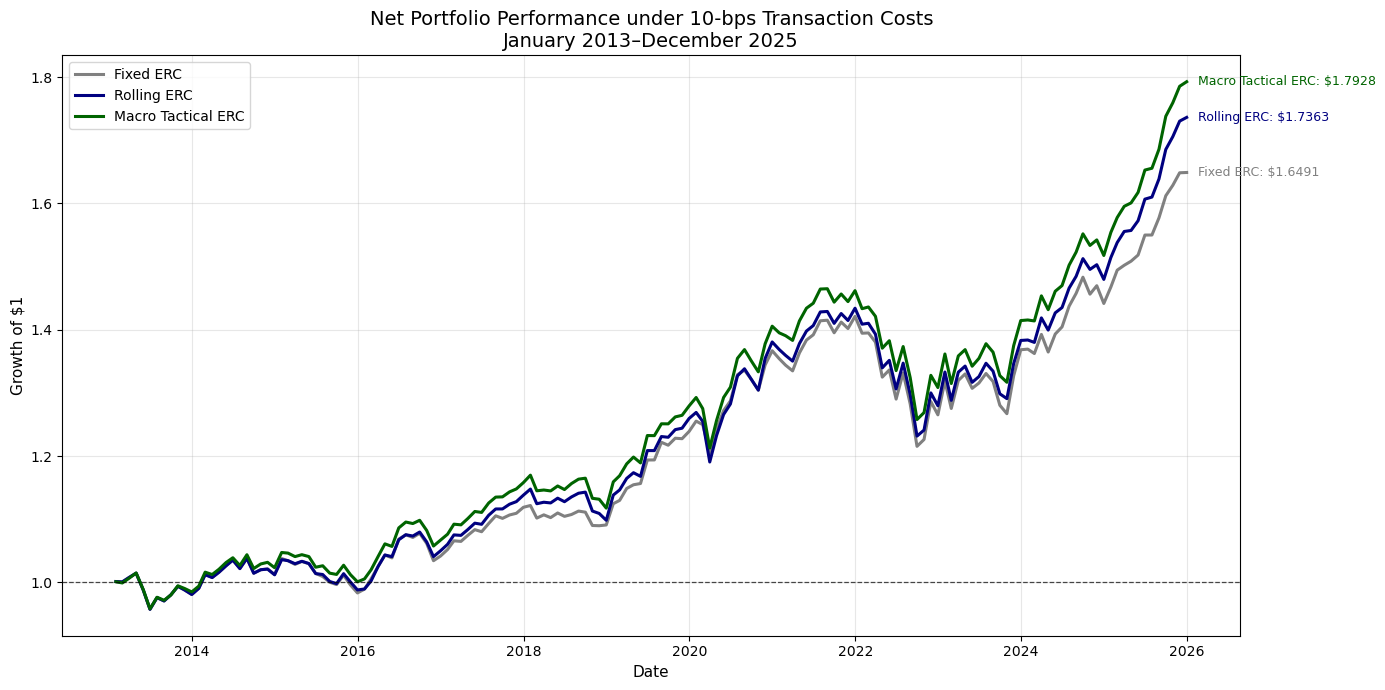

In [39]:
# ---------------------------------------------------------
# Plot cumulative net performance with 10-bps costs
# ---------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(14, 7)
)

plot_colors = {
    "Fixed ERC": "gray",
    "Rolling ERC": "navy",
    "Macro Tactical ERC": "darkgreen"
}

for strategy_name in (
    net_cumulative_comparison_10bps.columns
):

    ax.plot(
        net_cumulative_comparison_10bps.index,
        net_cumulative_comparison_10bps[
            strategy_name
        ],
        label=strategy_name,
        color=plot_colors[strategy_name],
        linewidth=2.2
    )

ax.axhline(
    y=1,
    color="black",
    linestyle="--",
    linewidth=0.9,
    alpha=0.7
)

ax.set_title(
    "Net Portfolio Performance under 10-bps Transaction Costs\n"
    "January 2013–December 2025",
    fontsize=14
)

ax.set_xlabel(
    "Date",
    fontsize=11
)

ax.set_ylabel(
    "Growth of $1",
    fontsize=11
)

ax.grid(
    alpha=0.3
)

ax.legend(
    loc="upper left"
)

# Label each strategy's final value.
for strategy_name in (
    net_cumulative_comparison_10bps.columns
):

    final_value = (
        net_cumulative_comparison_10bps[
            strategy_name
        ].iloc[-1]
    )

    ax.annotate(
        f"{strategy_name}: ${final_value:.4f}",
        xy=(
            net_cumulative_comparison_10bps.index[-1],
            final_value
        ),
        xytext=(8, 0),
        textcoords="offset points",
        fontsize=9,
        color=plot_colors[strategy_name],
        va="center"
    )

plt.tight_layout()
plt.show()

In [40]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# ---------------------------------------------------------
# Drawdown series under 10-bps transaction costs
# ---------------------------------------------------------

drawdown_10bps = pd.DataFrame(
    index=net_cumulative_comparison_10bps.index
)

for strategy_name in net_cumulative_comparison_10bps.columns:

    cumulative_wealth = (
        net_cumulative_comparison_10bps[strategy_name]
    )

    running_peak = cumulative_wealth.cummax()

    drawdown_10bps[strategy_name] = (
        cumulative_wealth / running_peak - 1
    )

# Maximum drawdown and corresponding date
drawdown_summary = pd.DataFrame({
    "Maximum Drawdown":
        drawdown_10bps.min(),

    "Maximum Drawdown Date":
        drawdown_10bps.idxmin()
})

drawdown_summary.style.format({
    "Maximum Drawdown": "{:.2%}",
    "Maximum Drawdown Date":
        lambda date: date.strftime("%Y-%m-%d")
})

,Maximum Drawdown,Maximum Drawdown Date
Fixed ERC,-14.49%,2022-09-30
Rolling ERC,-14.12%,2022-09-30
Macro Tactical ERC,-14.15%,2022-09-30


In [41]:
# ---------------------------------------------------------
# Maximum drawdown episode details
# ---------------------------------------------------------

def calculate_drawdown_episode(cumulative_wealth):

    running_peak = cumulative_wealth.cummax()
    drawdown = cumulative_wealth / running_peak - 1

    trough_date = drawdown.idxmin()
    maximum_drawdown = drawdown.loc[trough_date]

    peak_date = cumulative_wealth.loc[
        :trough_date
    ].idxmax()

    peak_value = cumulative_wealth.loc[peak_date]

    after_trough = cumulative_wealth.loc[
        trough_date:
    ]

    recovery_dates = after_trough[
        after_trough >= peak_value
    ]

    if len(recovery_dates) > 0:
        recovery_date = recovery_dates.index[0]
        recovery_months = (
            recovery_date.to_period("M")
            - trough_date.to_period("M")
        ).n
    else:
        recovery_date = pd.NaT
        recovery_months = np.nan

    decline_months = (
        trough_date.to_period("M")
        - peak_date.to_period("M")
    ).n

    if pd.notna(recovery_date):
        total_underwater_months = (
            recovery_date.to_period("M")
            - peak_date.to_period("M")
        ).n
    else:
        total_underwater_months = np.nan

    return {
        "Maximum Drawdown": maximum_drawdown,
        "Peak Date": peak_date,
        "Trough Date": trough_date,
        "Recovery Date": recovery_date,
        "Decline Months": decline_months,
        "Recovery Months": recovery_months,
        "Total Underwater Months":
            total_underwater_months
    }


drawdown_episode_summary = pd.DataFrame({
    strategy_name:
        calculate_drawdown_episode(
            net_cumulative_comparison_10bps[
                strategy_name
            ]
        )
    for strategy_name
    in net_cumulative_comparison_10bps.columns
}).T

drawdown_episode_summary

,Maximum Drawdown,Peak Date,Trough Date,Recovery Date,Decline Months,Recovery Months,Total Underwater Months
Fixed ERC,-0.144857,2021-12-31,2022-09-30,2024-07-31,9,22,31
Rolling ERC,-0.141242,2021-12-31,2022-09-30,2024-06-30,9,21,30
Macro Tactical ERC,-0.141462,2021-08-31,2022-09-30,2024-06-30,13,21,34


In [42]:
# ---------------------------------------------------------
# Additional drawdown statistics
# ---------------------------------------------------------

additional_drawdown_statistics = []

for strategy_name in drawdown_10bps.columns:

    strategy_drawdown = (
        drawdown_10bps[strategy_name]
    )

    underwater_drawdowns = strategy_drawdown[
        strategy_drawdown < 0
    ]

    average_drawdown = (
        underwater_drawdowns.mean()
    )

    underwater_ratio = (
        strategy_drawdown.lt(0).mean()
    )

    ulcer_index = np.sqrt(
        np.mean(strategy_drawdown ** 2)
    )

    additional_drawdown_statistics.append({
        "Strategy": strategy_name,
        "Average Drawdown":
            average_drawdown,
        "Underwater Month Ratio":
            underwater_ratio,
        "Ulcer Index":
            ulcer_index
    })

additional_drawdown_statistics = (
    pd.DataFrame(
        additional_drawdown_statistics
    ).set_index("Strategy")
)

additional_drawdown_statistics.style.format({
    "Average Drawdown": "{:.2%}",
    "Underwater Month Ratio": "{:.2%}",
    "Ulcer Index": "{:.2%}"
})

,Average Drawdown,Underwater Month Ratio,Ulcer Index
Strategy,,,
Fixed ERC,-3.30%,65.38%,3.67%
Rolling ERC,-3.19%,65.38%,3.59%
Macro Tactical ERC,-3.22%,63.46%,3.56%




# Portfolio Performance Comparison under 10-Basis-Point Transaction Costs

## 1. Comparison Objective

The purpose of this section is to compare three progressively more dynamic portfolio-allocation strategies:

1. Fixed ERC;
2. Rolling ERC;
3. Macro Tactical ERC.

The comparison separates two potential sources of value added:

$$
\text{Dynamic Risk Allocation}
$$

and:

$$
\text{Macro-Driven Tactical Allocation}.
$$

The first comparison is:

$$
\text{Rolling ERC}
-
\text{Fixed ERC},
$$

which measures whether updating portfolio weights using more recent volatility and covariance information improves performance.

The second comparison is:

$$
\text{Macro Tactical ERC}
-
\text{Rolling ERC},
$$

which measures whether macroeconomic information provides additional value beyond dynamic risk-based allocation.

All reported net results use a transaction-cost assumption of:

$$
10\text{ basis points}
=
0.10\%
$$

per unit of one-way portfolio turnover.

Transaction costs are calculated as:

$$
TC_t
=
Turnover_t
\times
0.10\%.
$$

Therefore, a monthly turnover of 3% produces a portfolio-level transaction cost of:

$$
3\%
\times
0.10\%
=
0.003\%.
$$

The 10-basis-point assumption represents an estimated combined implementation cost that includes bid–ask spreads, regulatory charges, slippage, and potential market impact. It is not an explicit brokerage commission applied to the entire portfolio every month.

---

## 2. Strategy 1: Fixed ERC

The Fixed ERC portfolio uses the covariance matrix estimated from the initial 2008–2012 training period.

The ERC optimizer determines capital weights such that the seven risky assets make approximately equal contributions to total portfolio volatility.

The resulting initial portfolio contains:

- 95% allocated across the seven risky assets;
- 5% allocated to Cash.

After the initial portfolio is constructed, the Fixed ERC target allocation is not re-estimated during the 2013–2025 evaluation period.

The Fixed ERC strategy can therefore be represented as:

$$
\mathbf w_t^{Fixed}
=
\mathbf w_{2013}^{ERC}.
$$

Because the target allocation remains unchanged, the strategy has no subsequent target-weight turnover after the initial portfolio formation. The initial formation cost is excluded from all three strategies.

Fixed ERC serves as the least dynamic control portfolio.

---

## 3. Strategy 2: Rolling ERC

The Rolling ERC portfolio updates its strategic target weights once per year.

For each portfolio year, the covariance matrix is estimated using the previous 60 months of asset returns:

$$
\Sigma_t
=
\operatorname{Cov}
\left(
R_{t-59},\ldots,R_t
\right).
$$

The ERC optimizer then calculates new weights using the updated covariance matrix:

$$
\mathbf w_y^{Rolling}
=
ERC\left(\Sigma_{y-1}\right).
$$

For example, the 2013 strategic weights use returns from January 2008 through December 2012.

The weights remain unchanged within each calendar year and are updated at the beginning of the following year.

Accordingly:

- volatility and correlation information are updated annually;
- the Cash allocation remains fixed at 5%;
- transaction costs occur only when annual target weights change.

Rolling ERC serves as the primary strategic benchmark.

---

## 4. Strategy 3: Macro Tactical ERC

The Macro Tactical ERC portfolio begins with the Rolling ERC strategic weights:

$$
\mathbf w_t^{Strategic}.
$$

It then uses the macro-factor model developed in Part 2 to predict the next-month excess returns of the seven risky assets.

The macro model uses five factors:

1. Growth;
2. Inflation;
3. Interest Rates;
4. Credit Conditions;
5. Risk Sentiment.

For each month, the predicted excess returns are ranked across the seven assets.

The ranks are converted into centered signals:

$$
-1,\;
-\frac23,\;
-\frac13,\;
0,\;
\frac13,\;
\frac23,\;
1.
$$

The baseline strategy uses a maximum tactical tilt of 2 percentage points:

$$
\Delta w_{i,t}^{Macro}
=
0.02s_{i,t}.
$$

Therefore, the possible tactical adjustments are:

$$
-2.00\%,
-1.33\%,
-0.67\%,
0.00\%,
0.67\%,
1.33\%,
2.00\%.
$$

The final Macro Tactical ERC weights are:

$$
\mathbf w_t^{Macro}
=
\mathbf w_t^{Rolling}
+
\Delta\mathbf w_t^{Macro}.
$$

Because the macro signals are centered:

$$
\sum_{i=1}^{7}
\Delta w_{i,t}^{Macro}
=
0.
$$

The tactical overlay therefore reallocates capital among the seven risky assets without changing total portfolio exposure or the 5% Cash allocation.

The macro signals are updated monthly. As a result, Macro Tactical ERC generally has higher turnover than Rolling ERC and is charged transaction costs whenever its target weights change.

---

## 5. Net Performance Results

After applying a transaction cost of 10 basis points per unit of turnover, the portfolio results from January 2013 through December 2025 are:

| Portfolio | Final Value | Total Return | CAGR | Annualized Volatility | Sharpe Ratio | Maximum Drawdown |
|---|---:|---:|---:|---:|---:|---:|
| Fixed ERC | $1.6491 | 64.91% | 3.92% | 5.89% | 0.408 | -14.49% |
| Rolling ERC | $1.7363 | 73.63% | 4.34% | 6.02% | 0.468 | -14.12% |
| Macro Tactical ERC | $1.7928 | 79.28% | 4.59% | 6.01% | 0.510 | -14.15% |

---

## 6. Fixed ERC versus Rolling ERC

Rolling ERC produces a higher total return than Fixed ERC:

$$
73.63\%-64.91\%
=
8.72\%.
$$

Its CAGR increases from:

$$
3.92\%
$$

to:

$$
4.34\%.
$$

The Sharpe ratio also improves:

$$
0.408
\longrightarrow
0.468.
$$

Maximum drawdown improves slightly:

$$
-14.49\%
\longrightarrow
-14.12\%.
$$

These results suggest that periodically updating ERC weights using more recent volatility and covariance information provides value relative to maintaining the initial allocation.

However, the improvement is not achieved through lower volatility. Annualized volatility increases slightly from 5.89% to 6.02%.

The benefit primarily appears through higher returns and a better return-to-risk ratio.

---

## 7. Rolling ERC versus Macro Tactical ERC

After transaction costs, Macro Tactical ERC produces a final portfolio value of:

$$
\$1.7928,
$$

compared with:

$$
\$1.7363
$$

for Rolling ERC.

The total-return improvement is:

$$
79.28\%-73.63\%
=
5.65\text{ percentage points}.
$$

The net CAGR increases from:

$$
4.34\%
$$

to:

$$
4.59\%.
$$

Therefore, the macro overlay adds approximately:

$$
4.59\%-4.34\%
=
0.26\%
$$

of annualized return after transaction costs.

This is approximately:

$$
26\text{ basis points per year}.
$$

At the same time, annualized volatility remains almost unchanged:

$$
6.02\%
\longrightarrow
6.01\%.
$$

The Sharpe ratio improves from:

$$
0.468
$$

to:

$$
0.510.
$$

Maximum drawdown changes only slightly:

$$
-14.12\%
\longrightarrow
-14.15\%.
$$

Therefore, the macro overlay increases net return and Sharpe ratio without materially increasing total portfolio volatility or maximum drawdown.

---

## 8. Active-Management Results

Relative to Rolling ERC, the Macro Tactical ERC portfolio generates:

| Active-Management Metric | Result |
|---|---:|
| Annualized Net Active Return | 0.25% |
| Tracking Error | 0.47% |
| Information Ratio | 0.530 |
| Positive Active Month Ratio | 57.69% |
| Newey–West t-statistic | 2.475 |
| Newey–West p-value | 0.0133 |

The information ratio is:

$$
IR
=
\frac{
0.25\%
}{
0.47\%
}
=
0.530.
$$

This indicates that the macro overlay generates approximately 0.53 units of annualized active return for each unit of active risk.

The positive active-month ratio is:

$$
57.69\%.
$$

Therefore, Macro Tactical ERC outperforms Rolling ERC in more than half of the monthly observations.

The Newey–West hypothesis test evaluates:

$$
H_0:
E\left[
R_t^{Macro}
-
R_t^{Rolling}
\right]
=
0.
$$

The resulting p-value is:

$$
p=0.0133.
$$

Because:

$$
0.0133<0.05,
$$

the net active return is statistically significant at the 5% level after adjusting for potential heteroskedasticity and serial correlation.

---

## 9. Tactical-Tilt Robustness Test

To examine whether the results depend entirely on the selected 2% tilt parameter, the strategy is also evaluated using maximum tilts of 1% and 3%.

All three scenarios use a 10-basis-point transaction-cost assumption.

| Tactical Tilt | Final Value | Total Return | CAGR | Volatility | Sharpe Ratio | Maximum Drawdown | Annualized Turnover |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1% | $1.7645 | 76.45% | 4.46% | 6.01% | 0.489 | -14.04% | 22.66% |
| 2% | $1.7928 | 79.28% | 4.59% | 6.01% | 0.510 | -14.15% | 41.34% |
| 3% | $1.8215 | 82.15% | 4.72% | 6.02% | 0.530 | -14.31% | 60.19% |

All three scenarios satisfy:

$$
w_{i,t}\geq0
$$

and:

$$
\sum_iw_{i,t}=1.
$$

The minimum portfolio weights are:

| Tactical Tilt | Minimum Weight |
|---|---:|
| 1% | 4.91% |
| 2% | 3.91% |
| 3% | 2.91% |

Therefore, all strategies remain fully invested and long-only.

The results show that stronger tactical tilts generate higher historical returns and Sharpe ratios, but also produce higher turnover and slightly larger maximum drawdowns.

The 3% strategy has the strongest historical performance, but it should not automatically be selected as the preferred strategy. Selecting it solely because it performs best in the historical sample would introduce parameter-selection bias.

The 2% tilt remains the baseline because it represents a moderate compromise between:

- macro-signal implementation;
- active return;
- tracking error;
- turnover;
- transaction costs;
- portfolio stability.

---

## 10. Overall Interpretation

The results support a three-stage allocation process:

$$
\boxed{
\text{Fixed ERC}
\rightarrow
\text{Rolling ERC}
\rightarrow
\text{Macro Tactical ERC}
}
$$

Fixed ERC provides the initial risk-balanced portfolio.

Rolling ERC improves the strategic allocation by updating the covariance matrix and portfolio weights as market risk relationships change.

Macro Tactical ERC adds a controlled monthly overlay based on macroeconomic predictions of relative asset performance.

The empirical results suggest that:

1. updating risk-based weights improves performance relative to keeping the initial ERC allocation fixed;
2. macroeconomic factors contain statistically significant information about subsequent relative asset performance;
3. the macro signals can be translated into modest tactical tilts;
4. the tactical strategy continues to outperform after transaction costs;
5. the improvement is achieved without materially increasing portfolio volatility or maximum drawdown;
6. the results remain positive across 1%, 2%, and 3% tactical-tilt specifications.

The findings do not imply that macro factors can precisely predict individual monthly asset returns. Instead, they indicate that macroeconomic information can modestly improve the relative ranking of asset classes and add incremental value when implemented as a constrained overlay around a diversified strategic benchmark.